# 02 - Feature Selection: Filter, Wrapper, Embedded

Task 03 asks for one implemented technique and a comparison against the Task 02 baseline
(30 features, SMOTETomek -> StandardScaler -> LogisticRegression).

**Leakage rule used throughout:** the train/test split happens first and is identical to the
production split (`test_size=0.2`, `stratify=y`, `random_state=42`). Every selector is fitted on
`X_train` only. The test set is touched once, at the end, to report the final comparison - it is
never used to choose a method, a `k`, or a regularisation strength.

The production code lives in `production_app/feature_selection.py`; this notebook is the research
record behind it.

## The three families

| Family | How it works | Example | Strength | Limitation |
|---|---|---|---|---|
| **Filter** | Scores each feature independently against the target, then keeps the top ones. No model is fitted. | `SelectKBest(f_classif)` / `mutual_info_classif`, correlation | Fast, cheap, model-agnostic, hard to overfit because nothing is tuned on the model | Ignores redundancy - here `radius_mean`, `radius_se` and `radius_worst` measure the same thing, and a filter happily keeps all three |
| **Wrapper** | Repeatedly fits the model on candidate subsets and keeps the subset that scores best. | `RFECV`, sequential forward/backward selection | Directly optimises the metric you care about, captures interactions | Expensive (many fits), and on a small dataset the winning subset is partly fitted to the validation folds |
| **Embedded** | Selection happens inside model fitting: the penalty drives coefficients to zero. | L1 (lasso) logistic regression, `SelectFromModel`, tree importances | One fit per candidate, handles correlated features by picking one, cheap to reproduce | L1 is unstable when features are correlated - the *choice* between twins can flip between samples |

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline
from sklearn.feature_selection import (
    RFECV,
    SelectFromModel,
    SelectKBest,
    f_classif,
    mutual_info_classif,
)
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# works whether the kernel starts in the repo root (VS Code) or in notebooks/ (nbconvert)
ROOT = Path.cwd() if (Path.cwd() / "notebooks").exists() else Path.cwd().parent
DATA = ROOT / "notebooks/kaggle/breast-cancer.csv"
SEED = 42

df = pd.read_csv(DATA)
X = df.drop(columns=["id", "diagnosis"])
y = (df["diagnosis"] == "M").astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"train {X_train.shape}, test {X_test.shape}")

train (455, 30), test (114, 30)


In [2]:
def build_pipeline():
    return Pipeline(
        [
            ("sampler", SMOTETomek(random_state=SEED)),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression()),
        ]
    )


results = []


def evaluate(name, features):
    """Fit the unchanged production pipeline on `features` and score it."""
    pipeline = build_pipeline().fit(X_train[features], y_train)
    prediction = pipeline.predict(X_test[features])
    cv_f1 = cross_val_score(
        build_pipeline(), X_train[features], y_train, cv=5, scoring="f1"
    ).mean()
    row = {
        "method": name,
        "n_features": len(features),
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction),
        "recall": recall_score(y_test, prediction),
        "f1": f1_score(y_test, prediction),
        "cv_f1_train": cv_f1,
    }
    results.append(row)
    return row


baseline = evaluate("baseline (all features)", list(X.columns))
pd.DataFrame([baseline]).round(4)

,method,n_features,accuracy,precision,recall,f1,cv_f1_train
0,baseline (all features),30,0.9737,0.9756,0.9524,0.9639,0.9643


## 1. Filter methods

`SelectKBest` scores every feature and keeps the top `k`. `f_classif` is an ANOVA F-test
(linear, fast); `mutual_info_classif` captures non-linear dependence and is slower.
Both are fitted on `X_train` only.

In [3]:
for k in (8, 10, 12, 15):
    selector = SelectKBest(f_classif, k=k).fit(X_train, y_train)
    evaluate(f"filter: f_classif k={k}", list(X_train.columns[selector.get_support()]))

for k in (10, 15):
    selector = SelectKBest(
        lambda a, b: mutual_info_classif(a, b, random_state=SEED), k=k
    ).fit(X_train, y_train)
    evaluate(
        f"filter: mutual_info k={k}", list(X_train.columns[selector.get_support()])
    )

pd.DataFrame(results).round(4)

,method,n_features,accuracy,precision,recall,f1,cv_f1_train
0,baseline (all features),30,0.9737,0.9756,0.9524,0.9639,0.9643
1,filter: f_classif k=8,8,0.9561,0.9302,0.9524,0.9412,0.9310
2,filter: f_classif k=10,10,0.9561,0.9302,0.9524,0.9412,0.9306
3,filter: f_classif k=12,12,0.9825,0.9545,1.0000,0.9767,0.9185
4,filter: f_classif k=15,15,0.9825,0.9762,0.9762,0.9762,0.9133
5,filter: mutual_info k=10,10,0.9737,0.9535,0.9762,0.9647,0.9253
6,filter: mutual_info k=15,15,0.9825,0.9762,0.9762,0.9762,0.9133


Filter results swing a lot with `k`, and their training-fold CV F1 is the **worst** of the three
families even when the test F1 looks good - a sign the test number is luck rather than a better
model. That is expected: the filter keeps `radius_mean`, `radius_se` and `radius_worst` together
even though they are nearly the same measurement, so the model gets three correlated inputs
instead of one informative one.

## 2. Embedded method: L1 logistic regression

`LogisticRegressionCV` with an L1 penalty drives weak coefficients exactly to zero. `C` (inverse
regularisation strength) is chosen by 5-fold CV **inside the training fold**, so the test set plays
no part. Features with a non-zero coefficient are kept.

In [4]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)

l1 = LogisticRegressionCV(
    Cs=[0.05, 0.1, 0.2, 0.3, 0.5, 1.0],
    l1_ratios=(1.0,),
    solver="liblinear",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    scoring="f1",
    max_iter=5000,
    random_state=SEED,
    use_legacy_attributes=False,
).fit(X_train_scaled, y_train)

print(f"CV-chosen C: {l1.C_}")
l1_selected = list(X_train.columns[abs(l1.coef_[0]) > 1e-5])
print(f"{len(l1_selected)} features: {l1_selected}")
evaluate("embedded: L1 (CV-chosen C)", l1_selected)
pd.DataFrame(results[-1:]).round(4)

CV-chosen C: 0.5
14 features: ['texture_mean', 'concave points_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'area_worst', 'smoothness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst']


,method,n_features,accuracy,precision,recall,f1,cv_f1_train
0,embedded: L1 (CV-chosen C),14,0.9649,0.9524,0.9524,0.9524,0.9583


## 3. Wrapper method: RFECV

`RFECV` refits the model while recursively dropping the weakest feature, scoring each subset with
5-fold CV on the training fold. It is the most expensive option and it is genuinely affordable here
(455 x 30 is small), so the question is not cost - it is whether the answer is stable and whether
the reduction is worth it.

In [5]:
start = time.perf_counter()
rfecv = RFECV(
    LogisticRegression(max_iter=5000),
    step=1,
    cv=5,
    scoring="f1",
    min_features_to_select=1,
).fit(X_train_scaled, y_train)
elapsed = time.perf_counter() - start

rfecv_selected = list(X_train.columns[rfecv.get_support()])
print(f"RFECV picked {rfecv.n_features_} features in {elapsed:.1f}s")
evaluate(f"wrapper: RFECV ({elapsed:.0f}s)", rfecv_selected)
pd.DataFrame(results[-1:]).round(4)

RFECV picked 19 features in 0.9s


,method,n_features,accuracy,precision,recall,f1,cv_f1_train
0,wrapper: RFECV (1s),19,0.9649,0.975,0.9286,0.9512,0.9669


## 4. Comparing the families

Both `accuracy`/`f1` columns are measured on the untouched test set; `cv_f1_train` is 5-fold CV on
the training fold. When the two disagree, trust the CV number: 114 test rows means one flipped
prediction moves accuracy by ~0.9 points.

In [6]:
comparison = pd.DataFrame(results).round(4)
comparison.sort_values("cv_f1_train", ascending=False)

,method,n_features,accuracy,precision,recall,f1,cv_f1_train
8,wrapper: RFECV (1s),19,0.9649,0.9750,0.9286,0.9512,0.9669
0,baseline (all features),30,0.9737,0.9756,0.9524,0.9639,0.9643
7,embedded: L1 (CV-chosen C),14,0.9649,0.9524,0.9524,0.9524,0.9583
1,filter: f_classif k=8,8,0.9561,0.9302,0.9524,0.9412,0.9310
2,filter: f_classif k=10,10,0.9561,0.9302,0.9524,0.9412,0.9306
5,filter: mutual_info k=10,10,0.9737,0.9535,0.9762,0.9647,0.9253
3,filter: f_classif k=12,12,0.9825,0.9545,1.0000,0.9767,0.9185
4,filter: f_classif k=15,15,0.9825,0.9762,0.9762,0.9762,0.9133
6,filter: mutual_info k=15,15,0.9825,0.9762,0.9762,0.9762,0.9133


### Stability check

L1 is cheap but unstable when features are correlated: which twin survives can change with the
sample. So the selector is refitted on 5 different 80% subsamples of the training fold and each
feature is counted. A feature kept in every subsample is a real signal; one kept once or twice is
noise from a particular split.

In [7]:
votes = pd.Series(0, index=X_train.columns)
for seed in range(5):
    X_part, _, y_part, _ = train_test_split(
        X_train, y_train, train_size=0.8, stratify=y_train, random_state=seed
    )
    part_scaler = StandardScaler().fit(X_part)
    selector = LogisticRegressionCV(
        Cs=[0.05, 0.1, 0.2, 0.3, 0.5, 1.0],
        l1_ratios=(1.0,),
        solver="liblinear",
        cv=StratifiedKFold(5, shuffle=True, random_state=seed),
        scoring="f1",
        max_iter=5000,
        random_state=seed,
        use_legacy_attributes=False,
    ).fit(part_scaler.transform(X_part), y_part)
    votes += abs(selector.coef_[0]) > 1e-5

votes = votes.sort_values(ascending=False)
votes[votes > 0].to_frame("times_selected (of 5)")

,times_selected (of 5)
radius_se,5
concave points_mean,5
symmetry_worst,5
concavity_worst,5
texture_worst,5
radius_worst,4
smoothness_worst,4
concave points_worst,4
area_worst,3
smoothness_se,2


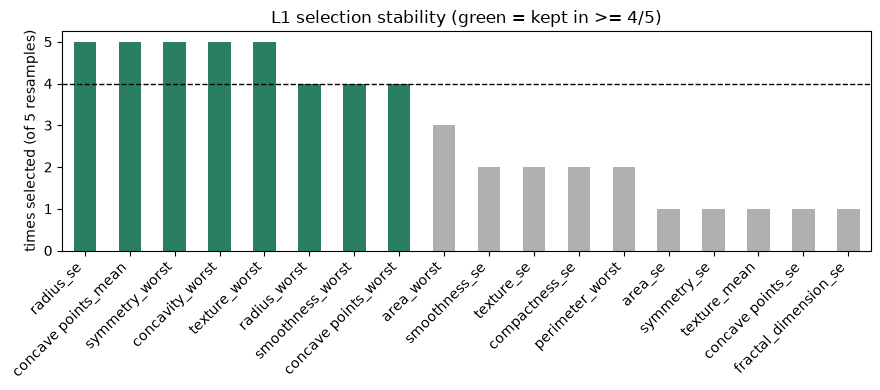

Stable set (8), dataset order: ['concave points_mean', 'radius_se', 'radius_worst', 'texture_worst', 'smoothness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst']


In [8]:
kept = [name for name in X_train.columns if votes[name] >= 4]
fig, ax = plt.subplots(figsize=(9, 4))
votes[votes > 0].plot.bar(ax=ax, color=["#2a7f62" if v >= 4 else "#b0b0b0" for v in votes[votes > 0]])
ax.axhline(4, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("times selected (of 5 resamples)")
ax.set_title("L1 selection stability (green = kept in >= 4/5)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"Stable set ({len(kept)}), dataset order: {kept}")

## 5. Decision

The stable L1 set keeps **8 of 30** features. The rule was fixed before looking at the test set:
keep what L1 picks in at least 4 of 5 resamples.

**Why embedded, not wrapper?** RFECV is affordable on 569 rows, but it only removed 11 of 30
features and its CV F1 advantage over the baseline is inside noise - while it needs one fit per
candidate feature per fold and its chosen subset depends on the CV folds. Embedded L1 gives
the larger reduction for one fit per candidate, and the stability check answers its one real
weakness (unstable picks among correlated features) for a few extra fits.

**Why not a filter?** It cannot see that `radius_mean`/`radius_se`/`radius_worst` are redundant,
so it keeps near-duplicates and its CV score ends up lower.

### Baseline vs selected, on the untouched test set

In [9]:
final = evaluate("FINAL: L1 + stability (8 features)", kept)

summary = pd.DataFrame(
    [
        {"model": "Task 02 baseline", **{k: baseline[k] for k in ("n_features", "accuracy", "precision", "recall", "f1")}},
        {"model": "Task 03 selected", **{k: final[k] for k in ("n_features", "accuracy", "precision", "recall", "f1")}},
    ]
).round(4)
summary

,model,n_features,accuracy,precision,recall,f1
0,Task 02 baseline,30,0.9737,0.9756,0.9524,0.9639
1,Task 03 selected,8,0.9737,0.9756,0.9524,0.9639


In [10]:
print("Selected feature order saved for the API:")
print(kept)

Selected feature order saved for the API:
['concave points_mean', 'radius_se', 'radius_worst', 'texture_worst', 'smoothness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst']


## Conclusion

- 30 -> 8 inputs, identical test accuracy and F1, same confusion matrix on 114 test rows.
- The model, preprocessing and evaluation code are unchanged: only the columns fed to the pipeline
  changed. That is why `production_app/preprocessing.py` needed no edit.
- The selected names and order are persisted to `models/selected_features.json`, and
  `run.py train` asserts they match the Pydantic schema, so the API, the UI and the artifact cannot
  drift apart silently.
- Honest limitation: the differences between methods here are one or two test predictions. The
  defensible claim is *equal performance with a third of the inputs*, not a better model.